# PRCFX-DT++ Fusion — Mixture of Experts (with Validation Set)

Late-fusion classifier for 30 virus classes. The Stream A CNN embedding and the Stream B PageRank vector are concatenated and passed through a gated mixture of expert MLPs.

## Setup

| Aspect | Setting |
|---|---|
| Data splits | 70 % train / 10 % val / 20 % test |
| Checkpoint criterion | Best **validation** macro F1 |
| Scheduler signal | `scheduler.step(val_f1)` |
| Epochs | Up to 50 (early stopping on val F1, patience=8) |
| Test set | Evaluated once, at the very end |
| Stream A source | `output_streamA_val/` |
| Stream B val embeddings | Derived by index-slicing `X_train_sequences.npy` |
| Gate usage averaging | Weighted by batch size |
| Ablation standard fusion | Read from `output_fusion_standard_val/` |
| Timer | Per-epoch + total wall-clock time |

## Architecture

```
z = [e_A (256-dim) | e_B (64-dim)]    ← concatenated, standardised (320-dim)
         │
    ┌────┴────────────────────────────┐
    │       Gating Network            │
    │   Linear(320,64)→ReLU→Linear(64,E)→Softmax   │   g ∈ ℝ^E
    └────┬──────────────────────────┬─┘
    ┌────▼────┐      ┌────▼────┐  ...
    │ Expert 1│      │ Expert 2│
    │ BN→256  │      │ BN→256  │   Each expert: BN→Lin(320,256)→BN→ReLU→Drop(0.3)
    │ →128→30 │      │ →128→30 │                  →Lin(256,128)→BN→ReLU→Drop(0.2)→Lin(128,30)
    └────┬────┘      └────┬────┘
         └───────┬────────┘
              Σ g_e · logits_e  →  30-class output
```

E=4, λ_aux=0.01, GATE_HIDDEN=64.

## Stream A artefacts

The CNN embeddings are loaded from `output_streamA_val/`, where the best checkpoint was selected on validation macro F1, so the test set plays no part in selecting the CNN.

## Gate usage

Per-epoch gate usage is accumulated as `gate.sum(dim=0)` over all samples and divided by the total sample count, so a smaller final batch (e.g. 38 instead of 64 samples) is not over-weighted.


## 1 · Imports

In [1]:
# Imports

import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score,
)
import joblib

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import sklearn
print(f'NumPy   {np.__version__}')
print(f'Pandas  {pd.__version__}')
print(f'sklearn {sklearn.__version__}')
print(f'torch   {torch.__version__}')

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'\nDevice: {DEVICE}')

NumPy   2.4.4
Pandas  3.0.2
sklearn 1.8.0
torch   2.11.0+cpu

Device: cpu


## 2 · Paths

In [2]:
# Paths and artefact verification
#
# Stream A: output_streamA_val/ (val-based model selection, three-file embedding export).
# Stream B: output_streamB/.
# Standard fusion: output_fusion_standard_val/, read for the ablation table.

DATA_DIR     = Path(r'..\data\processed')
STREAM_A_DIR = Path('output_streamA_val')
STREAM_B_DIR = Path('output_streamB')
STD_FUSE_DIR = Path('output_fusion_standard_val')
OUTPUT_DIR   = Path('output_fusion_moe_val')
OUTPUT_DIR.mkdir(exist_ok=True)

RAW_CSV = DATA_DIR / 'all_viruses_sequences.csv'
if not RAW_CSV.exists():
    RAW_CSV = Path('all_viruses_sequences.csv')
if not RAW_CSV.exists():
    raise FileNotFoundError('Cannot find all_viruses_sequences.csv.')

# ── Stream A artefacts ────────────────
STREAM_A_MODEL   = STREAM_A_DIR / 'stream_a_val_cnn_model.pt'
STREAM_A_EMB_TR  = STREAM_A_DIR / 'stream_a_val_embeddings_train.npy'
STREAM_A_EMB_VA  = STREAM_A_DIR / 'stream_a_val_embeddings_val.npy'
STREAM_A_EMB_TE  = STREAM_A_DIR / 'stream_a_val_embeddings_test.npy'

# ── Stream B artefacts (two-file) ───────────────────
STREAM_B_FEAT_TR = STREAM_B_DIR / 'X_train_sequences.npy'
STREAM_B_FEAT_TE = STREAM_B_DIR / 'X_test_sequences.npy'
STREAM_B_LAB_TR  = STREAM_B_DIR / 'y_train_sequences.npy'
STREAM_B_LAB_TE  = STREAM_B_DIR / 'y_test_sequences.npy'

required = [
    STREAM_A_MODEL, STREAM_A_EMB_TR, STREAM_A_EMB_VA, STREAM_A_EMB_TE,
    STREAM_B_FEAT_TR, STREAM_B_FEAT_TE, STREAM_B_LAB_TR, STREAM_B_LAB_TE,
]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError(
        'Missing artefacts. Run the StreamA (output_streamA_val/) '
        'and StreamB (output_streamB/) notebooks first.\n'
        + '\n'.join(f'  {m}' for m in missing)
    )

print('All required artefacts found.')
print(f'Stream A dir : {STREAM_A_DIR}')
print(f'Stream B dir : {STREAM_B_DIR}')
print(f'Output dir   : {OUTPUT_DIR}')

All required artefacts found.
Stream A dir : output_streamA_val
Stream B dir : output_streamB
Output dir   : output_fusion_moe_val


## 3 · Hyperparameters

In [3]:
# Hyperparameters
#
# VAL_SIZE is 0.125 of the train+val pool (~10 % of total). It must match the split
# used in the Stream A notebook (test_size=0.125, random_state=43) so that the
# Stream B arrays can be sliced with the same row positions.
#
# Scheduler patience (5) is shorter than the early-stop patience (8), so the LR
# can drop at least once before training stops.

# ── Fusion input dimensions ──────────────────────
DIM_A      = 256
DIM_B      = 64
DIM_JOINT  = DIM_A + DIM_B   # 320

# ── MoE architecture ─────────────────────────────
NUM_EXPERTS   = 4
DIM_EXPERT_H1 = 256
DIM_EXPERT_H2 = 128
DROP_E1       = 0.30
DROP_E2       = 0.20
GATE_HIDDEN   = 64
LAMBDA_AUX    = 0.01

# ── Training ──────────────────────────────────────────────────
BATCH_SIZE    = 64
LEARNING_RATE = 5e-4
TEST_SIZE     = 0.20
VAL_SIZE      = 0.125         # 12.5 % of trainval → ~10 % of total
MIN_SEQ_LEN   = 500
VALID_NTS     = set('ACGT')

NUM_EPOCHS           = 50
EARLY_STOP_PATIENCE  = 8

print(f'Joint dim            : {DIM_JOINT}')
print(f'Experts              : {NUM_EXPERTS}')
print(f'Expert arch          : {DIM_JOINT}→{DIM_EXPERT_H1}→{DIM_EXPERT_H2}→num_classes')
print(f'Gate hidden          : {GATE_HIDDEN}')
print(f'Lambda_aux           : {LAMBDA_AUX}')
print(f'Batch size           : {BATCH_SIZE}')
print(f'Learning rate        : {LEARNING_RATE}')
print(f'Val fraction         : {VAL_SIZE}')
print(f'Epochs               : {NUM_EPOCHS}')
print(f'Early-stop patience  : {EARLY_STOP_PATIENCE} epochs')

Joint dim            : 320
Experts              : 4
Expert arch          : 320→256→128→num_classes
Gate hidden          : 64
Lambda_aux           : 0.01
Batch size           : 64
Learning rate        : 0.0005
Val fraction         : 0.125
Epochs               : 50
Early-stop patience  : 8 epochs


## 4 · Reconstruct label encoder and three-way split

In [4]:
# Label encoder and three-way split
#
# Row alignment between the Stream A and Stream B embedding arrays is the key
# invariant of the fusion pipeline. A different split (even just a different seed)
# would silently pair the CNN embedding of sequence i with the PageRank vector of
# sequence j and produce meaningless results with no error.
#
#   Step 1: train_test_split(df, test_size=0.20, random_state=42)
#     -> df_trainval (80 %), df_test (20 %)
#   Step 2: train_test_split(df_trainval, test_size=0.125, random_state=43)
#     -> df_train (~70 % of total), df_val (~10 % of total)
#
# train_idx / val_idx are the row positions within df_trainval_reset from Step 2.
# The next cell uses them to slice Stream B's X_train_sequences.npy.

def clean_sequence(seq: str) -> str:
    return ''.join(c for c in seq.upper().strip() if c in VALID_NTS)


df_raw = pd.read_csv(RAW_CSV)
df_raw['sequence'] = df_raw['sequence'].astype(str)
df = df_raw.copy()
df['sequence'] = df['sequence'].apply(clean_sequence)
df['length']   = df['sequence'].str.len()
df = df[df['length'] >= MIN_SEQ_LEN].reset_index(drop=True)

le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['virus'])
class_names = list(le.classes_)
num_classes = len(class_names)

# Step 1 — (train+val) 80 % vs test 20 %
df_trainval, df_test = train_test_split(
    df, test_size=TEST_SIZE, random_state=SEED, stratify=df['label_enc']
)

# Step 2 — train 87.5 % vs val 12.5 % of trainval
df_trainval_reset = df_trainval.reset_index(drop=True)
df_train_sub, df_val_sub = train_test_split(
    df_trainval_reset,
    test_size=VAL_SIZE, random_state=SEED + 1,
    stratify=df_trainval_reset['label_enc'],
)

df_train = df_train_sub.reset_index(drop=True)
df_val   = df_val_sub.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

y_train = df_train['label_enc'].values
y_val   = df_val['label_enc'].values
y_test  = df_test['label_enc'].values

# Integer positions within df_trainval_reset for Stream B slicing
train_idx = df_train_sub.index.values
val_idx   = df_val_sub.index.values

n_total = len(df)
print(f'Classes : {num_classes}')
print(f'\nThree-way split:')
print(f'  Train : {len(df_train):,}  ({len(df_train)/n_total*100:.1f} %)')
print(f'  Val   : {len(df_val):,}  ({len(df_val)/n_total*100:.1f} %)')
print(f'  Test  : {len(df_test):,}  ({len(df_test)/n_total*100:.1f} %)')
for split_name, split_y in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    n_cls = len(np.unique(split_y))
    print(f'  {split_name} : {n_cls}/{num_classes} classes  {"✓" if n_cls == num_classes else "WARNING"}')

Classes : 30

Three-way split:
  Train : 121,226  (70.0 %)
  Val   : 17,319  (10.0 %)
  Test  : 34,637  (20.0 %)
  Train : 30/30 classes  ✓
  Val : 30/30 classes  ✓
  Test : 30/30 classes  ✓


## 5 · Load embeddings and derive Stream B validation split

In [5]:
# Load embeddings and derive the Stream B val split
#
# Stream A: three .npy files (train / val / test).
#
# Stream B: two .npy files (train = 80 % pool, test = 20 %). Val embeddings are
# recovered by slicing X_train_sequences.npy with train_idx / val_idx from the
# previous cell. This is valid because the rows of that array follow
# df_trainval_reset (same deterministic split, random_state=42) and the indices
# come from the second split (random_state=43, test_size=0.125). The label
# assertions below check the alignment at runtime.

# ── Stream A ────────────────────────
emb_a_train = np.load(STREAM_A_EMB_TR)   # (n_train, 256)
emb_a_val   = np.load(STREAM_A_EMB_VA)   # (n_val,   256)
emb_a_test  = np.load(STREAM_A_EMB_TE)   # (n_test,  256)

# ── Stream B (slice to recover val) ─────────────────
emb_b_trainval_full = np.load(STREAM_B_FEAT_TR)   # (n_trainval, 64)
emb_b_test          = np.load(STREAM_B_FEAT_TE)   # (n_test, 64)
y_b_trainval_full   = np.load(STREAM_B_LAB_TR)
y_b_test            = np.load(STREAM_B_LAB_TE)

emb_b_train = emb_b_trainval_full[train_idx]
emb_b_val   = emb_b_trainval_full[val_idx]
y_b_train   = y_b_trainval_full[train_idx]
y_b_val     = y_b_trainval_full[val_idx]

# ── Alignment verification ────────────────────────────────────
assert emb_a_train.shape[0] == emb_b_train.shape[0], (
    f'Train size mismatch: A={emb_a_train.shape[0]}, B={emb_b_train.shape[0]}')
assert emb_a_val.shape[0] == emb_b_val.shape[0], (
    f'Val size mismatch: A={emb_a_val.shape[0]}, B={emb_b_val.shape[0]}')
assert emb_a_test.shape[0] == emb_b_test.shape[0], (
    f'Test size mismatch: A={emb_a_test.shape[0]}, B={emb_b_test.shape[0]}')
np.testing.assert_array_equal(y_b_train, y_train,
    err_msg='Train labels: Stream B vs reconstructed split disagree.')
np.testing.assert_array_equal(y_b_val, y_val,
    err_msg='Val labels: Stream B vs reconstructed split disagree.')
np.testing.assert_array_equal(y_b_test, y_test,
    err_msg='Test labels: Stream B vs reconstructed split disagree.')

print('Alignment verification passed  ✓')
print(f'\nEmbedding shapes:')
print(f'  Stream A train : {emb_a_train.shape}')
print(f'  Stream A val   : {emb_a_val.shape}')
print(f'  Stream A test  : {emb_a_test.shape}')
print(f'  Stream B train : {emb_b_train.shape}')
print(f'  Stream B val   : {emb_b_val.shape}')
print(f'  Stream B test  : {emb_b_test.shape}')
print(f'  A train range  : [{emb_a_train.min():.3f}, {emb_a_train.max():.3f}]')
print(f'  B train range  : [{emb_b_train.min():.5f}, {emb_b_train.max():.5f}]  (PageRank)')

Alignment verification passed  ✓

Embedding shapes:
  Stream A train : (121226, 256)
  Stream A val   : (17319, 256)
  Stream A test  : (34637, 256)
  Stream B train : (121226, 64)
  Stream B val   : (17319, 64)
  Stream B test  : (34637, 64)
  A train range  : [0.000, 15.331]
  B train range  : [0.00000, 0.48742]  (PageRank)


## 6 · Normalise and concatenate

In [6]:
# Normalise and concatenate
#
# StandardScaler is fitted on train only and applied with .transform() to val and
# test. Without normalisation the 256 A dims have a ~100x larger L2 norm than the
# 64 B dims, which mutes Stream B in the first projection of each expert
# (Atrey et al., 2010). Separate scalers for A and B keep the within-stream scale
# contrast while equalising the cross-stream contribution.

scaler_a = StandardScaler()
scaler_b = StandardScaler()

emb_a_train_s = scaler_a.fit_transform(emb_a_train)
emb_b_train_s = scaler_b.fit_transform(emb_b_train)

emb_a_val_s   = scaler_a.transform(emb_a_val)
emb_b_val_s   = scaler_b.transform(emb_b_val)
emb_a_test_s  = scaler_a.transform(emb_a_test)
emb_b_test_s  = scaler_b.transform(emb_b_test)

X_train = np.concatenate([emb_a_train_s, emb_b_train_s], axis=1)  # (n_train, 320)
X_val   = np.concatenate([emb_a_val_s,   emb_b_val_s],   axis=1)  # (n_val,   320)
X_test  = np.concatenate([emb_a_test_s,  emb_b_test_s],  axis=1)  # (n_test,  320)

print('Joint feature matrices:')
print(f'  X_train : {X_train.shape}   mean={X_train.mean():.4f}  std={X_train.std():.4f}')
print(f'  X_val   : {X_val.shape}   mean={X_val.mean():.4f}  std={X_val.std():.4f}')
print(f'  X_test  : {X_test.shape}   mean={X_test.mean():.4f}  std={X_test.std():.4f}')

Joint feature matrices:
  X_train : (121226, 320)   mean=-0.0000  std=0.6824
  X_val   : (17319, 320)   mean=-0.0014  std=0.6797
  X_test  : (34637, 320)   mean=-0.0011  std=0.6799


## 7 · Dataset and DataLoaders

In [7]:
# Dataset and DataLoaders
#
# WeightedRandomSampler is used on the training loader only; val and test loaders
# use shuffle=False and no sampler.

class FusionDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        assert X.shape[0] == y.shape[0]
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self) -> int:
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


def make_weighted_sampler(y: np.ndarray) -> WeightedRandomSampler:
    unique, counts = np.unique(y, return_counts=True)
    cw = np.zeros(y.max() + 1, dtype=np.float64)
    for cls, cnt in zip(unique, counts):
        cw[cls] = 1.0 / cnt
    sw = torch.tensor([cw[lbl] for lbl in y], dtype=torch.float64)
    return WeightedRandomSampler(weights=sw, num_samples=len(y), replacement=True)


train_dataset = FusionDataset(X_train, y_train)
val_dataset   = FusionDataset(X_val,   y_val)
test_dataset  = FusionDataset(X_test,  y_test)

sampler = make_weighted_sampler(y_train)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          sampler=sampler, num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=0)

print(f'Train batches : {len(train_loader)}')
print(f'Val   batches : {len(val_loader)}')
print(f'Test  batches : {len(test_loader)}')

Train batches : 1895
Val   batches : 271
Test  batches : 542


## 8 · Mixture of Experts architecture

In [8]:
# MoE architecture
#
# ExpertMLP    : one expert — BN→Lin(320,256)→BN→ReLU→Drop(0.3)
#                              →Lin(256,128)→BN→ReLU→Drop(0.2)→Lin(128,30)
# GatingNetwork: Linear(320,64)→ReLU→Linear(64,E)→Softmax
# MoEFusion    : combined_logits = Σ_e g_e · f_e(z)


class ExpertMLP(nn.Module):
    """
    A single expert: 2-layer MLP.
    Input : (batch, dim_in)
    Output: (batch, num_classes) — unnormalised logits
    """
    def __init__(self, dim_in, hidden1, hidden2, num_classes,
                 drop1=0.3, drop2=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.BatchNorm1d(dim_in),
            nn.Linear(dim_in, hidden1),
            nn.BatchNorm1d(hidden1),
            nn.ReLU(inplace=True),
            nn.Dropout(p=drop1),
            nn.Linear(hidden1, hidden2),
            nn.BatchNorm1d(hidden2),
            nn.ReLU(inplace=True),
            nn.Dropout(p=drop2),
            nn.Linear(hidden2, num_classes),
        )

    def forward(self, x):
        return self.net(x)


class GatingNetwork(nn.Module):
    """
    Lightweight gating network.
    Output: (batch, E) — softmax-normalised routing weights, summing to 1.
    Intentionally smaller than the experts to avoid the gate memorising
    class labels directly (Shazeer et al., 2017).
    """
    def __init__(self, dim_in, gate_hidden, num_experts):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim_in, gate_hidden),
            nn.ReLU(inplace=True),
            nn.Linear(gate_hidden, num_experts),
        )

    def forward(self, x):
        return F.softmax(self.net(x), dim=-1)   # (batch, E)


class MoEFusion(nn.Module):
    """
    Soft Mixture-of-Experts fusion (Jacobs et al., 1991).
    forward() returns (combined_logits, gates) for loss computation
    and routing interpretability.
    """
    def __init__(self, dim_in, gate_hidden, num_experts,
                 expert_h1, expert_h2, num_classes, drop1=0.3, drop2=0.2):
        super().__init__()
        self.num_experts = num_experts
        self.gate = GatingNetwork(dim_in, gate_hidden, num_experts)
        self.experts = nn.ModuleList([
            ExpertMLP(dim_in, expert_h1, expert_h2, num_classes, drop1, drop2)
            for _ in range(num_experts)
        ])

    def forward(self, x):
        gates = self.gate(x)                               # (batch, E)
        expert_logits = torch.stack(
            [expert(x) for expert in self.experts], dim=0  # (E, batch, C)
        )
        gates_expanded = gates.unsqueeze(-1)               # (batch, E, 1)
        expert_logits  = expert_logits.permute(1, 0, 2)   # (batch, E, C)
        combined_logits = (expert_logits * gates_expanded).sum(dim=1)  # (batch, C)
        return combined_logits, gates


moe_model = MoEFusion(
    dim_in=DIM_JOINT, gate_hidden=GATE_HIDDEN, num_experts=NUM_EXPERTS,
    expert_h1=DIM_EXPERT_H1, expert_h2=DIM_EXPERT_H2,
    num_classes=num_classes, drop1=DROP_E1, drop2=DROP_E2,
).to(DEVICE)

# Smoke test
_x = torch.randn(4, DIM_JOINT).to(DEVICE)
with torch.no_grad():
    _logits, _gates = moe_model(_x)
assert _logits.shape == (4, num_classes), f'Bad logit shape: {_logits.shape}'
assert _gates.shape  == (4, NUM_EXPERTS), f'Bad gate shape: {_gates.shape}'
assert abs(_gates.sum(dim=1).mean().item() - 1.0) < 1e-5, 'Gates must sum to 1'

total_params = sum(p.numel() for p in moe_model.parameters())
print('MoE architecture loaded')
print(f'  Total parameters : {total_params:,}')
print(f'  Gate check (sample 0): {_gates[0].cpu().numpy().round(3)}  sum={_gates[0].sum():.5f}')

MoE architecture loaded
  Total parameters : 502,204
  Gate check (sample 0): [0.295 0.223 0.175 0.306]  sum=1.00000


## 9 · Loss function with auxiliary load-balance term

In [9]:
# MoE loss
#
# L_total = L_CE + λ · L_aux
#
# L_aux = Σ_e ḡ_e · log(ḡ_e)   where ḡ = batch-mean gate  (= −H(ḡ))
#
# Maximising H(ḡ) (uniform utilisation across samples) prevents expert collapse
# (Shazeer et al., 2017, importance-loss variant). A per-sample entropy would push
# each sample to use all experts equally and prevent specialisation.

ce_criterion = nn.CrossEntropyLoss()

def moe_loss(logits, gates, labels, lambda_aux=LAMBDA_AUX):
    """
    Returns (total_loss, ce_loss_scalar, aux_loss_scalar).
    """
    l_ce       = ce_criterion(logits, labels)
    mean_gate  = gates.mean(dim=0).clamp(min=1e-9)          # (E,)
    l_aux      = (mean_gate * torch.log(mean_gate)).sum()   # = -H(ḡ) ≤ 0
    total      = l_ce + lambda_aux * l_aux
    return total, l_ce.item(), l_aux.item()


print(f'Loss = CrossEntropy + {LAMBDA_AUX} × (−H(batch-mean gate))')
print('L_aux < 0  →  gate is spread across experts (healthy).')
print('L_aux → 0  →  gate collapses to one expert (pathological).')

Loss = CrossEntropy + 0.01 × (−H(batch-mean gate))
L_aux < 0  →  gate is spread across experts (healthy).
L_aux → 0  →  gate collapses to one expert (pathological).


## 10 · Training utilities

In [10]:
# Training utilities
#
# train_one_epoch_moe accumulates gate usage as a sum over samples and divides by
# the total sample count, so a smaller final batch is not over-weighted.

def train_one_epoch_moe(model, loader, optimizer, device, lambda_aux):
    model.train()
    total_loss_sum = 0.0
    ce_sum = 0.0
    aux_sum = 0.0
    gate_sum = np.zeros(NUM_EXPERTS, dtype=np.float64)
    N_samples = 0
    y_true, y_pred = [], []

    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits, gates = model(X_batch)
        total, ce, aux = moe_loss(logits, gates, y_batch, lambda_aux)
        total.backward()
        optimizer.step()

        n = X_batch.size(0)
        total_loss_sum += total.item() * n
        ce_sum  += ce  * n
        aux_sum += aux * n
        gate_sum   += gates.detach().cpu().numpy().sum(axis=0)   # sum over batch dim
        N_samples  += n
        preds = torch.argmax(logits, dim=1)
        y_true.extend(y_batch.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

    mean_gate_usage = gate_sum / N_samples   # unbiased per-expert mean

    return (
        total_loss_sum / N_samples,
        ce_sum / N_samples,
        aux_sum / N_samples,
        accuracy_score(y_true, y_pred),
        f1_score(y_true, y_pred, average='macro', zero_division=0),
        mean_gate_usage,
    )


def evaluate_moe(model, loader, device, lambda_aux):
    """Evaluate on a loader: loss, accuracy, macro F1, labels, predictions, gates."""
    model.eval()
    total_loss_sum = 0.0
    y_true, y_pred = [], []
    gate_log = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits, gates = model(X_batch)
            total, _, _ = moe_loss(logits, gates, y_batch, lambda_aux)
            total_loss_sum += total.item() * X_batch.size(0)
            preds = torch.argmax(logits, dim=1)
            y_true.extend(y_batch.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            gate_log.append(gates.cpu().numpy())

    N = len(loader.dataset)
    all_gates = np.concatenate(gate_log, axis=0)   # (n_eval, E)

    return (
        total_loss_sum / N,
        accuracy_score(y_true, y_pred),
        f1_score(y_true, y_pred, average='macro', zero_division=0),
        np.array(y_true),
        np.array(y_pred),
        all_gates,
    )


print('Training utilities loaded.')

Training utilities loaded.


## 11 · Training loop with validation, early stopping, and timer

In [11]:
# Training loop
#
# - Checkpoint: best_state_dict is saved when validation macro F1 improves.
# - Scheduler: ReduceLROnPlateau on validation F1 (patience=5).
# - Early stopping: stops after EARLY_STOP_PATIENCE epochs without val F1 gain.
# - Timer: per-epoch and total wall-clock time with time.perf_counter().
# - Gate usage is logged per epoch for train and val.
# - The test set is not evaluated inside this loop.

optimizer = torch.optim.Adam(
    moe_model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', patience=5, factor=0.5
)

history           = []
best_val_f1       = -np.inf
best_state_dict   = None
epochs_no_improve = 0

total_train_start = time.perf_counter()

print(f'Starting training for up to {NUM_EPOCHS} epochs '
      f'(early stop patience={EARLY_STOP_PATIENCE}).')
print(f'Checkpoint criterion : best VALIDATION macro F1.')
print(f'Test set             : evaluated ONCE after training ends.')
print('-' * 110)

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.perf_counter()

    tr_loss, tr_ce, tr_aux, tr_acc, tr_f1, tr_gate = train_one_epoch_moe(
        moe_model, train_loader, optimizer, DEVICE, LAMBDA_AUX
    )
    va_loss, va_acc, va_f1, _, _, va_gates = evaluate_moe(
        moe_model, val_loader, DEVICE, LAMBDA_AUX
    )

    scheduler.step(va_f1)

    epoch_secs = time.perf_counter() - epoch_start
    current_lr = optimizer.param_groups[0]['lr']

    gate_str = ' '.join(f'{g:.3f}' for g in tr_gate)

    history.append({
        'epoch'        : epoch,
        'train_loss'   : tr_loss, 'train_ce': tr_ce, 'train_aux': tr_aux,
        'train_acc'    : tr_acc,  'train_f1': tr_f1,
        'val_loss'     : va_loss, 'val_acc' : va_acc, 'val_f1'  : va_f1,
        'lr'           : current_lr,
        'epoch_time_s' : epoch_secs,
        **{f'gate_train_e{i}': tr_gate[i] for i in range(NUM_EXPERTS)},
        **{f'gate_val_e{i}':   float(va_gates.mean(axis=0)[i])
           for i in range(NUM_EXPERTS)},
    })

    improved = va_f1 > best_val_f1
    if improved:
        best_val_f1       = va_f1
        best_state_dict   = {k: v.cpu().clone()
                             for k, v in moe_model.state_dict().items()}
        epochs_no_improve = 0
        marker = '  ✓ new best val F1'
    else:
        epochs_no_improve += 1
        marker = f'  (no improve {epochs_no_improve}/{EARLY_STOP_PATIENCE})'

    print(
        f'Ep {epoch:02d}/{NUM_EPOCHS} | '
        f'L={tr_loss:.4f} CE={tr_ce:.4f} aux={tr_aux:.4f} | '
        f'tr_f1={tr_f1:.4f} va_f1={va_f1:.4f} va_acc={va_acc:.4f} | '
        f'lr={current_lr:.2e} | gates=[{gate_str}] | {epoch_secs:.1f}s'
        + marker
    )

    if epochs_no_improve >= EARLY_STOP_PATIENCE:
        print(f'\nEarly stopping at epoch {epoch} '
              f'(no val F1 improvement for {EARLY_STOP_PATIENCE} epochs).')
        break

# ── Total time ────────────────────────────────────────────────
total_secs = time.perf_counter() - total_train_start
total_h    = int(total_secs // 3600)
total_m    = int((total_secs % 3600) // 60)
total_s    = total_secs % 60

print('-' * 110)
print('Training complete.')
print(f'  Best validation macro F1 : {best_val_f1:.4f}')
best_epoch = max(h['epoch'] for h in history if abs(h['val_f1'] - best_val_f1) < 1e-9)
print(f'  Achieved at epoch        : {best_epoch}')
print(f'  Total training time      : {total_h:02d}h {total_m:02d}m {total_s:04.1f}s')

Starting training for up to 50 epochs (early stop patience=8).
Checkpoint criterion : best VALIDATION macro F1.
Test set             : evaluated ONCE after training ends.
--------------------------------------------------------------------------------------------------------------
Ep 01/50 | L=0.0512 CE=0.0645 aux=-1.3306 | tr_f1=0.9957 va_f1=0.9264 va_acc=0.9923 | lr=5.00e-04 | gates=[0.210 0.211 0.365 0.214] | 44.8s  ✓ new best val F1
Ep 02/50 | L=-0.0115 CE=0.0018 aux=-1.3308 | tr_f1=0.9998 va_f1=0.9320 va_acc=0.9938 | lr=5.00e-04 | gates=[0.217 0.214 0.366 0.203] | 44.1s  ✓ new best val F1
Ep 03/50 | L=-0.0114 CE=0.0019 aux=-1.3315 | tr_f1=0.9999 va_f1=0.9375 va_acc=0.9939 | lr=5.00e-04 | gates=[0.226 0.208 0.364 0.203] | 44.3s  ✓ new best val F1
Ep 04/50 | L=-0.0118 CE=0.0015 aux=-1.3281 | tr_f1=1.0000 va_f1=0.9416 va_acc=0.9947 | lr=5.00e-04 | gates=[0.229 0.203 0.367 0.201] | 44.5s  ✓ new best val F1
Ep 05/50 | L=-0.0116 CE=0.0017 aux=-1.3289 | tr_f1=0.9999 va_f1=0.9344 va_acc=0

## 12 · Learning curves and gate utilisation  *(train and val only)*

,epoch,train_loss,train_ce,train_aux,train_acc,train_f1,val_loss,val_acc,val_f1,lr,epoch_time_s,gate_train_e0,gate_train_e1,gate_train_e2,gate_train_e3,gate_val_e0,gate_val_e1,gate_val_e2,gate_val_e3
0,1,0.0512,0.0645,-1.3306,0.9957,0.9957,0.0170,0.9923,0.9264,0.0005,44.8202,0.2104,0.2109,0.3649,0.2138,0.2840,0.2728,0.4024,0.0408
1,2,-0.0115,0.0018,-1.3308,0.9998,0.9998,0.0134,0.9938,0.9320,0.0005,44.1266,0.2173,0.2139,0.3663,0.2025,0.2961,0.2708,0.3967,0.0364
2,3,-0.0114,0.0019,-1.3315,0.9999,0.9999,0.0141,0.9939,0.9375,0.0005,44.3101,0.2256,0.2075,0.3638,0.2031,0.3611,0.2063,0.4003,0.0323
3,4,-0.0118,0.0015,-1.3281,1.0000,1.0000,0.0109,0.9947,0.9416,0.0005,44.4824,0.2290,0.2033,0.3667,0.2010,0.3704,0.1909,0.4082,0.0305
4,5,-0.0116,0.0017,-1.3289,0.9999,0.9999,0.0194,0.9921,0.9344,0.0005,44.1712,0.2279,0.2035,0.3678,0.2008,0.3685,0.1960,0.4065,0.0290
5,6,-0.0119,0.0014,-1.3272,0.9999,0.9999,0.0104,0.9951,0.9458,0.0005,44.4357,0.2269,0.2020,0.3701,0.2010,0.3745,0.1913,0.4030,0.0311
6,7,-0.0116,0.0017,-1.3285,0.9999,0.9999,0.0131,0.9940,0.9388,0.0005,44.2167,0.2298,0.2014,0.3668,0.2020,0.3719,0.1859,0.4138,0.0284
7,8,-0.0119,0.0014,-1.3289,0.9999,0.9999,0.0111,0.9944,0.9427,0.0005,44.4535,0.2278,0.2020,0.3676,0.2026,0.3709,0.1908,0.4089,0.0295
8,9,-0.0119,0.0014,-1.3266,1.0000,1.0000,0.0090,0.9951,0.9437,0.0005,44.0441,0.2290,0.2020,0.3695,0.1995,0.3712,0.1895,0.4093,0.0300
9,10,-0.0118,0.0014,-1.3285,0.9999,0.9999,0.0096,0.9950,0.9551,0.0005,44.0682,0.2284,0.2043,0.3662,0.2011,0.3757,0.1890,0.4048,0.0305


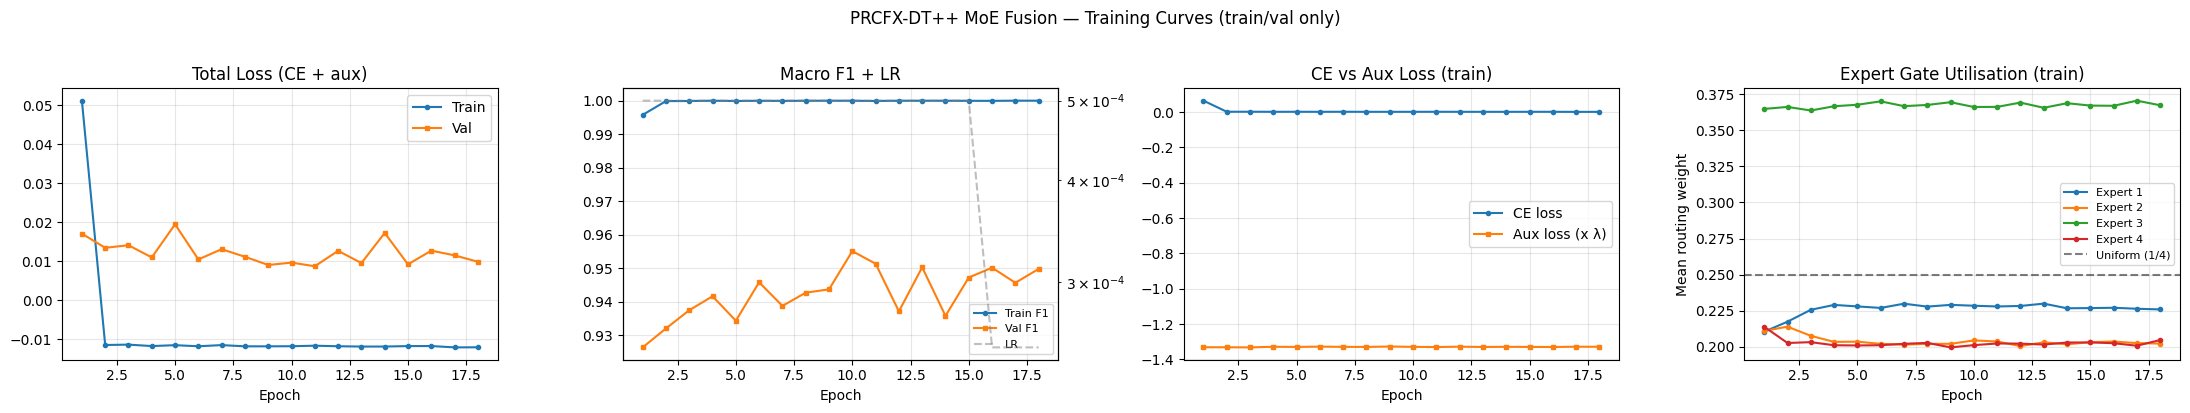


Training time statistics:
  Mean per epoch : 44.2 s
  Fastest epoch  : 44.0 s
  Slowest epoch  : 44.8 s


In [12]:
# Learning curves and gate utilisation over epochs (train and val only)

history_df = pd.DataFrame(history)
display(history_df.round(4))

fig, axes = plt.subplots(1, 4, figsize=(22, 4))

# Loss
axes[0].plot(history_df['epoch'], history_df['train_loss'],
             marker='o', markersize=3, label='Train')
axes[0].plot(history_df['epoch'], history_df['val_loss'],
             marker='s', markersize=3, label='Val')
axes[0].set_title('Total Loss (CE + aux)'); axes[0].set_xlabel('Epoch')
axes[0].legend(); axes[0].grid(alpha=0.3)

# Macro F1 + LR
ax_f1 = axes[1]
ax_lr = ax_f1.twinx()
ax_f1.plot(history_df['epoch'], history_df['train_f1'],
           marker='o', markersize=3, color='tab:blue', label='Train F1')
ax_f1.plot(history_df['epoch'], history_df['val_f1'],
           marker='s', markersize=3, color='tab:orange', label='Val F1')
ax_lr.semilogy(history_df['epoch'], history_df['lr'],
               linestyle='--', color='tab:grey', alpha=0.5, label='LR')
ax_f1.set_title('Macro F1 + LR'); ax_f1.set_xlabel('Epoch')
lines1, l1 = ax_f1.get_legend_handles_labels()
lines2, l2 = ax_lr.get_legend_handles_labels()
ax_f1.legend(lines1 + lines2, l1 + l2, fontsize=8)
ax_f1.grid(alpha=0.3)

# CE vs aux loss
axes[2].plot(history_df['epoch'], history_df['train_ce'],
             marker='o', markersize=3, label='CE loss')
axes[2].plot(history_df['epoch'], history_df['train_aux'],
             marker='s', markersize=3, label='Aux loss (x λ)')
axes[2].set_title('CE vs Aux Loss (train)'); axes[2].set_xlabel('Epoch')
axes[2].legend(); axes[2].grid(alpha=0.3)

# Expert gate utilisation (train)
for e in range(NUM_EXPERTS):
    col = f'gate_train_e{e}'
    if col in history_df.columns:
        axes[3].plot(history_df['epoch'], history_df[col],
                     marker='o', markersize=3, label=f'Expert {e+1}')
axes[3].axhline(1.0 / NUM_EXPERTS, color='black', linestyle='--',
               alpha=0.5, label=f'Uniform (1/{NUM_EXPERTS})')
axes[3].set_title('Expert Gate Utilisation (train)')
axes[3].set_xlabel('Epoch'); axes[3].set_ylabel('Mean routing weight')
axes[3].legend(fontsize=8); axes[3].grid(alpha=0.3)

plt.suptitle('PRCFX-DT++ MoE Fusion — Training Curves (train/val only)', y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fusion_moe_val_training_curves.png', dpi=150)
plt.show()

print(f'\nTraining time statistics:')
print(f'  Mean per epoch : {history_df["epoch_time_s"].mean():.1f} s')
print(f'  Fastest epoch  : {history_df["epoch_time_s"].min():.1f} s')
print(f'  Slowest epoch  : {history_df["epoch_time_s"].max():.1f} s')

## 13 · Final evaluation on the test set  *(one-shot)*

In [13]:
# Final evaluation: best checkpoint, test set, once

moe_model.load_state_dict(best_state_dict)

_, final_acc, final_f1, y_true, y_pred, final_gates = evaluate_moe(
    moe_model, test_loader, DEVICE, LAMBDA_AUX
)

print('=' * 60)
print('PRCFX-DT++ MoE FUSION — FINAL TEST RESULTS')
print('(best-val-F1 checkpoint; test set evaluated once)')
print('=' * 60)
print(f'  Test Accuracy : {final_acc:.4f}')
print(f'  Test Macro F1 : {final_f1:.4f}')
print()
print(classification_report(
    y_true, y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0,
))

PRCFX-DT++ MoE FUSION — FINAL TEST RESULTS
(best-val-F1 checkpoint; test set evaluated once)
  Test Accuracy : 0.9957
  Test Macro F1 : 0.9556

                 precision    recall  f1-score   support

         corona     1.0000    1.0000    1.0000     13012
 coxsackievirus     0.9707    0.9397    0.9550       282
  crimean-congo     1.0000    0.9655    0.9825        29
cytomegalovirus     0.9375    0.9677    0.9524        62
         dengue     0.9864    0.9932    0.9898      1609
          ebola     0.9861    0.9771    0.9816       437
   encephalitis     0.9091    0.7692    0.8333        26
            flu     0.9996    0.9989    0.9992     10635
    hepatitis b     1.0000    0.9964    0.9982      1678
    hepatitis c     0.9755    1.0000    0.9876       159
            hiv     0.9940    0.9995    0.9967      3671
          lassa     1.0000    0.9808    0.9903        52
        marburg     1.0000    0.9091    0.9524        11
 mastadenovirus     0.9785    0.9820    0.9803       278


## 14 · Confusion matrix

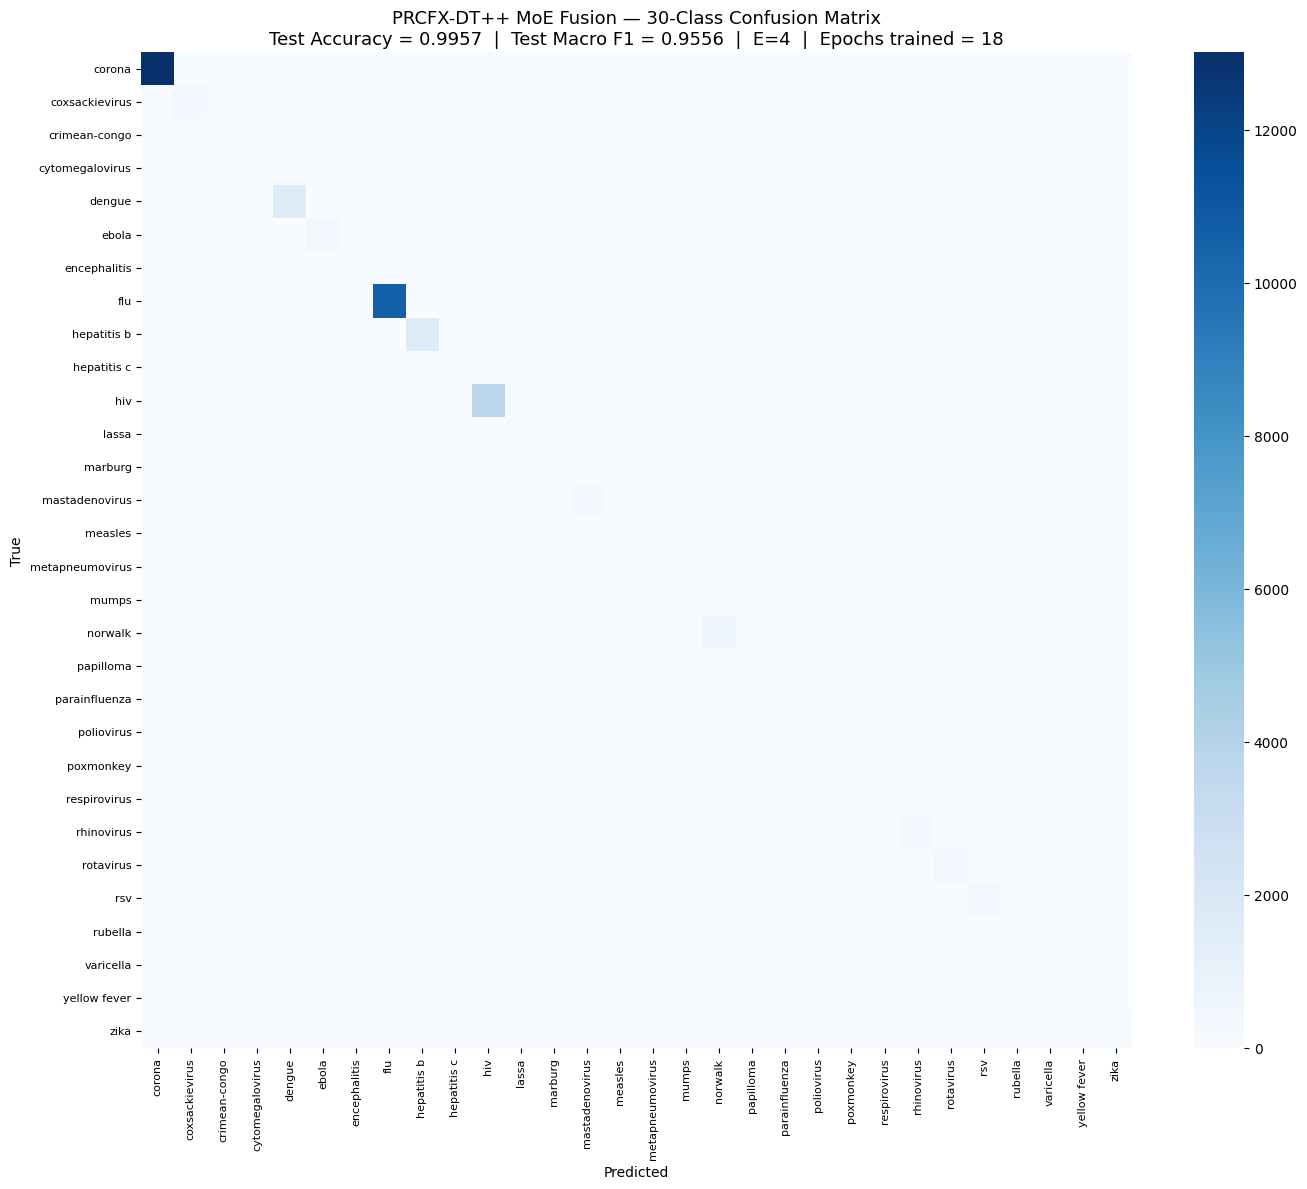

In [14]:
# 30-class confusion matrix

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, ax=ax, cmap='Blues', annot=False,
            xticklabels=class_names, yticklabels=class_names)
ax.set_title(
    f'PRCFX-DT++ MoE Fusion — 30-Class Confusion Matrix\n'
    f'Test Accuracy = {final_acc:.4f}  |  Test Macro F1 = {final_f1:.4f}  '
    f'|  E={NUM_EXPERTS}  |  Epochs trained = {len(history)}',
    fontsize=13
)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.tick_params(axis='x', rotation=90, labelsize=8)
ax.tick_params(axis='y', rotation=0,  labelsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fusion_moe_val_confusion_matrix.png', dpi=150)
plt.show()

## 15 · MoE interpretability — per-class expert routing

In [15]:
# Expert routing analysis per virus class
#
# Shows which expert the gating network routes each virus class to on the test
# set. If specialisation has occurred, different virus families should cluster to
# different experts. If all classes route to the same expert, expert collapse has
# occurred despite the load-balance loss and LAMBDA_AUX should be increased.

print('Expert routing analysis (mean gating weight per virus class):')
print()

routing_rows = []
for cls_idx, cls_name in enumerate(class_names):
    mask = (y_true == cls_idx)
    if mask.sum() == 0:
        continue
    mean_g = final_gates[mask].mean(axis=0)   # (E,)
    dominant_expert = int(np.argmax(mean_g)) + 1
    row = {'Virus': cls_name, 'Dominant Expert': dominant_expert}
    for e in range(NUM_EXPERTS):
        row[f'g_E{e+1}'] = round(float(mean_g[e]), 4)
    routing_rows.append(row)

routing_df = pd.DataFrame(routing_rows)
display(routing_df.to_string(index=False))
routing_df.to_csv(OUTPUT_DIR / 'moe_routing_analysis.csv', index=False)

Expert routing analysis (mean gating weight per virus class):



'          Virus  Dominant Expert   g_E1   g_E2   g_E3   g_E4\n         corona                3 0.0195 0.0095 0.9584 0.0126\n coxsackievirus                4 0.0101 0.0559 0.0162 0.9178\n  crimean-congo                1 0.9178 0.0362 0.0402 0.0059\ncytomegalovirus                4 0.0000 0.0000 0.0000 1.0000\n         dengue                2 0.0104 0.9831 0.0021 0.0045\n          ebola                2 0.0080 0.9534 0.0345 0.0041\n   encephalitis                2 0.0435 0.7773 0.0005 0.1786\n            flu                1 0.9798 0.0139 0.0020 0.0043\n    hepatitis b                1 0.9881 0.0071 0.0007 0.0041\n    hepatitis c                4 0.0010 0.0013 0.0000 0.9977\n            hiv                2 0.0130 0.9796 0.0042 0.0032\n          lassa                3 0.0287 0.1035 0.8618 0.0060\n        marburg                3 0.0084 0.0658 0.9214 0.0044\n mastadenovirus                4 0.0033 0.0166 0.0011 0.9790\n        measles                1 0.9064 0.0751 0.0076 0.0109\nmetapne

## 16 · Expert routing heatmap

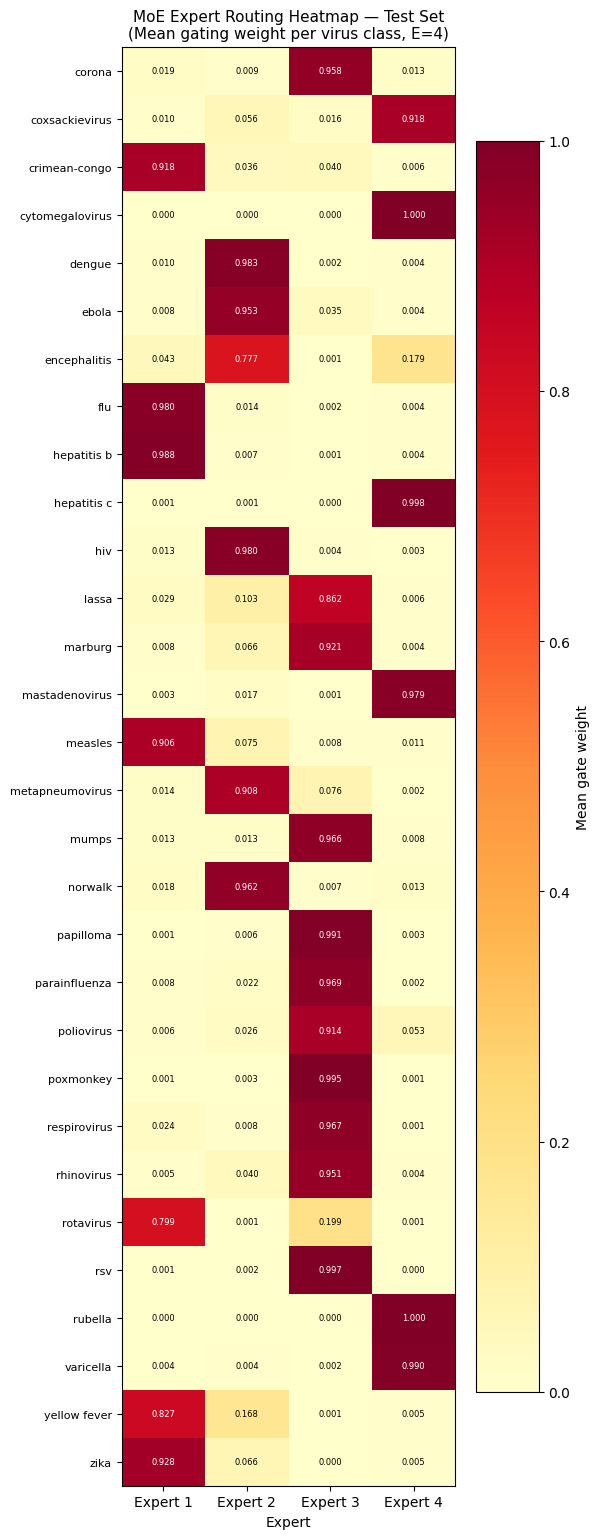

Heatmap saved to: output_fusion_moe_val\fusion_moe_val_routing_heatmap.png


In [16]:
# Gate routing heatmap

gate_cols   = [f'g_E{e+1}' for e in range(NUM_EXPERTS)]
gate_matrix = routing_df.set_index('Virus')[gate_cols].values   # (n_class, E)

fig, ax = plt.subplots(
    figsize=(max(6, NUM_EXPERTS * 1.5), len(class_names) * 0.45 + 2)
)
im = ax.imshow(gate_matrix, cmap='YlOrRd', aspect='auto', vmin=0.0)

ax.set_xticks(range(NUM_EXPERTS))
ax.set_xticklabels([f'Expert {e+1}' for e in range(NUM_EXPERTS)])
ax.set_yticks(range(len(routing_df)))
ax.set_yticklabels(routing_df['Virus'].values, fontsize=8)
ax.set_xlabel('Expert')
ax.set_title(
    f'MoE Expert Routing Heatmap — Test Set\n'
    f'(Mean gating weight per virus class, E={NUM_EXPERTS})',
    fontsize=11
)

for i in range(gate_matrix.shape[0]):
    for j in range(gate_matrix.shape[1]):
        ax.text(j, i, f'{gate_matrix[i,j]:.3f}',
                ha='center', va='center', fontsize=6,
                color='black' if gate_matrix[i, j] < 0.5 else 'white')

plt.colorbar(im, ax=ax, label='Mean gate weight')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fusion_moe_val_routing_heatmap.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('Heatmap saved to:', OUTPUT_DIR / 'fusion_moe_val_routing_heatmap.png')

## 17 · Expert collapse diagnostic

In [17]:
# Expert collapse diagnostic
#
# Entropy H(ḡ) of the mean gate distribution on the test set.
# Ideal: H(ḡ) ≈ log(E) = log(4) ≈ 1.386 (uniform routing).
# Collapse: H(ḡ) → 0 (one expert receives all weight).
# Threshold for concern: utilisation ratio H(ḡ)/log(E) < 0.5.
#
# If collapse is detected: increase LAMBDA_AUX, reduce NUM_EXPERTS, or train longer.

mean_gate_test = final_gates.mean(axis=0)    # (E,)
entropy_gate   = -np.sum(mean_gate_test * np.log(mean_gate_test + 1e-9))
max_entropy    = math.log(NUM_EXPERTS)

print('Expert utilisation on test set (best-val-F1 checkpoint):')
for e, g in enumerate(mean_gate_test):
    bar = '█' * int(g * 50)
    print(f'  Expert {e+1}: {g:.4f}  {bar}')

print(f'\nGate distribution entropy   : {entropy_gate:.4f}')
print(f'Max possible entropy (log E) : {max_entropy:.4f}')
print(f'Utilisation ratio            : {entropy_gate / max_entropy:.2%}')

underused = [e+1 for e, g in enumerate(mean_gate_test) if g < 0.05]
if underused:
    print(f'\n⚠  Underutilised experts (< 5%): {underused}')
    print('   Consider increasing LAMBDA_AUX or reducing NUM_EXPERTS.')
else:
    print('\n✓  All experts utilised above 5% — no collapse detected.')

Expert utilisation on test set (best-val-F1 checkpoint):
  Expert 1: 0.3758  ██████████████████
  Expert 2: 0.1891  █████████
  Expert 3: 0.4048  ████████████████████
  Expert 4: 0.0303  █

Gate distribution entropy   : 1.1548
Max possible entropy (log E) : 1.3863
Utilisation ratio            : 83.30%

⚠  Underutilised experts (< 5%): [4]
   Consider increasing LAMBDA_AUX or reducing NUM_EXPERTS.


## 18 · Ablation comparison table

In [18]:
# Ablation comparison table
#
# Stream A and standard fusion results are read from output_streamA_val/ and
# output_fusion_standard_val/. Stream A and both fusion rows use the best-val-F1
# checkpoint with the test set evaluated once; Stream B uses its CV-selected tree.

rows = []

sa_sum = STREAM_A_DIR / 'stream_a_val_summary.csv'
if sa_sum.exists():
    sa = pd.read_csv(sa_sum).iloc[0]
    rows.append({
        'System'      : 'Stream A — CPNR-GASF-CNN',
        'Accuracy'    : sa.get('final_test_acc',      float('nan')),
        'Macro F1'    : sa.get('final_test_macro_f1', float('nan')),
        'Checkpoint'  : 'best val F1',
    })
else:
    print(f'WARNING: {sa_sum} not found.')

sb_sum = STREAM_B_DIR / 'stream_b_summary.csv'
if sb_sum.exists():
    sb = pd.read_csv(sb_sum).iloc[0]
    rows.append({
        'System'      : 'Stream B — PRCFX-DT PageRank',
        'Accuracy'    : sb.get('test_acc',       float('nan')),
        'Macro F1'    : sb.get('test_macro_f1',  float('nan')),
        'Checkpoint'  : 'best CV score (DT)',
    })
else:
    print(f'WARNING: {sb_sum} not found.')

std_sum = STD_FUSE_DIR / 'fusion_standard_val_summary.csv'
if std_sum.exists():
    std = pd.read_csv(std_sum).iloc[0]
    rows.append({
        'System'      : 'Fusion — Standard MLP (A+B)',
        'Accuracy'    : std.get('final_test_acc',      float('nan')),
        'Macro F1'    : std.get('final_test_macro_f1', float('nan')),
        'Checkpoint'  : 'best val F1',
    })
else:
    print(f'WARNING: {std_sum} not found — run the standard fusion notebook first.')

rows.append({
    'System'      : f'Fusion — MoE (E={NUM_EXPERTS})',
    'Accuracy'    : round(float(final_acc), 4),
    'Macro F1'    : round(float(final_f1), 4),
    'Checkpoint'  : 'best val F1',
})

ablation_df = pd.DataFrame(rows)
print('Ablation Study Results')
print('=' * 70)
display(ablation_df.to_string(index=False))
ablation_df.to_csv(OUTPUT_DIR / 'ablation_study_moe_val.csv', index=False)

Ablation Study Results


'                      System  Accuracy  Macro F1         Checkpoint\n    Stream A — CPNR-GASF-CNN  0.975287  0.878983        best val F1\nStream B — PRCFX-DT PageRank  0.997575  0.982891 best CV score (DT)\n Fusion — Standard MLP (A+B)  0.996680  0.958486        best val F1\n          Fusion — MoE (E=4)  0.995700  0.955600        best val F1'

## 19 · Save all artefacts

In [19]:
# Save all artefacts

history_df.to_csv(OUTPUT_DIR / 'fusion_moe_val_training_history.csv', index=False)

joblib.dump(scaler_a, OUTPUT_DIR / 'scaler_a.joblib')
joblib.dump(scaler_b, OUTPUT_DIR / 'scaler_b.joblib')

np.save(OUTPUT_DIR / 'final_test_gates.npy', final_gates)

torch.save({
    'model_state_dict'       : best_state_dict,
    'class_names'            : class_names,
    'num_classes'            : num_classes,
    'dim_a'                  : DIM_A,
    'dim_b'                  : DIM_B,
    'dim_joint'              : DIM_JOINT,
    'num_experts'            : NUM_EXPERTS,
    'lambda_aux'             : LAMBDA_AUX,
    'best_val_macro_f1'      : best_val_f1,
    'final_test_acc'         : final_acc,
    'final_test_macro_f1'    : final_f1,
    'epochs_trained'         : len(history),
    'total_train_time_s'     : total_secs,
}, OUTPUT_DIR / 'fusion_moe_val_model.pt')

summary = pd.DataFrame([{
    'system'                 : 'PRCFX-DT++ MoE Fusion',
    'fusion_type'            : f'Mixture of Experts (E={NUM_EXPERTS})',
    'num_experts'            : NUM_EXPERTS,
    'lambda_aux'             : LAMBDA_AUX,
    'gate_entropy'           : round(float(entropy_gate),          6),
    'max_entropy'            : round(max_entropy,                   6),
    'utilisation_ratio'      : round(float(entropy_gate / max_entropy), 4),
    'dim_a'                  : DIM_A,
    'dim_b'                  : DIM_B,
    'dim_joint'              : DIM_JOINT,
    'num_classes'            : num_classes,
    'n_train'                : len(y_train),
    'n_val'                  : len(y_val),
    'n_test'                 : len(y_test),
    'epochs_trained'         : len(history),
    'best_val_macro_f1'      : round(float(best_val_f1),  6),
    'final_test_acc'         : round(float(final_acc),    6),
    'final_test_macro_f1'    : round(float(final_f1),     6),
    'total_train_time_s'     : round(total_secs,           1),
    'total_train_time_hms'   : f'{total_h:02d}h {total_m:02d}m {total_s:04.1f}s',
}])
summary.to_csv(OUTPUT_DIR / 'fusion_moe_val_summary.csv', index=False)
display(summary.T)
print(f'\nAll artefacts saved to: {OUTPUT_DIR}')

,0
system,PRCFX-DT++ MoE Fusion
fusion_type,Mixture of Experts (E=4)
num_experts,4
lambda_aux,0.01
gate_entropy,1.15481
max_entropy,1.386294
utilisation_ratio,0.833
dim_a,256
dim_b,64
dim_joint,320



All artefacts saved to: output_fusion_moe_val
